In [1]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import time
import torchvision.models as models
from matplotlib import pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

### Data Load

In [11]:
image_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [38]:
dataset_path = "dataset"

dataset = datasets.ImageFolder(dataset_path, transform = image_transforms)
len(dataset)

2300

In [39]:
dataset.classes

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [54]:
class_names = dataset.classes
class_names 

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [56]:
num_classes = len(dataset.classes)
num_classes

6

In [57]:
train_size = int(0.75*len(dataset))
val_size = len(dataset) - train_size
train_size, val_size

(1725, 575)

In [58]:
from torch.utils.data import random_split
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [59]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=True)

In [60]:
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [61]:
labels[2]

tensor(1)

In [62]:
images[2].shape

torch.Size([3, 224, 224])

In [63]:
images[2].permute(1, 2, 0).shape

torch.Size([224, 224, 3])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4831376].


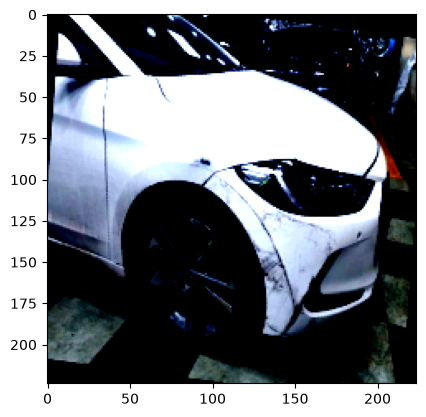

In [64]:
plt.imshow(images[2].permute(1, 2, 0))
plt.show()

### MODEL 1: cnn


In [66]:
class CarClassifierCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.network = nn.Sequential(

            # First Convolution Block
            nn.Conv2d(
                in_channels=3,
                out_channels=16,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Second Convolution Block
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Third Convolution Block
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Fully Connected Layers
            nn.Flatten(),

            nn.Linear(64 * 28 * 28, 512),
            nn.ReLU(),

            nn.Linear(512, num_classes)

        )

    def forward(self, x):
        return self.network(x)

In [67]:
#instantiate the model, loss function and optimizer

model = CarClassifierCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [69]:
len(train_loader.dataset)

1725

In [74]:
def train_model(model, criterion, optimizer, epochs=5):
    start = time.time()
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch_num, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)
            
            # Zero the parameter gradients
            optimizer.zero_grad()
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Backward pass and optimization
            loss.backward()
            optimizer.step()
            
            if (batch_num+1) % 10 == 0:
                print(f"Batch: {batch_num+1}, Epoch: {epoch+1}, Loss: {loss.item():0.2f}")
            
            running_loss += loss.item() * images.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        print(f"Epoch [{epoch+1}/{epochs}], Avg Loss: {epoch_loss:.4f}")

        # Validation
        model.eval()
        correct = 0
        total = 0
        all_labels = []
        all_predictions = []
        
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data,1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())
                
            print(f"*** Validation Accuracy: {100 * correct / total:.2f}% ***")
            
    end = time.time()
    print(f"Execution time: {end - start} seconds")     
    
    return all_labels, all_predictions

In [75]:
values, indices = torch.max(torch.tensor([[10, 12, 15, 9,2]]), 1)
values, indices

(tensor([15]), tensor([2]))

In [77]:
train_model(model, criterion, optimizer, epochs=3 )

Batch: 10, Epoch: 1, Loss: 1.78
Batch: 20, Epoch: 1, Loss: 1.78
Batch: 30, Epoch: 1, Loss: 1.73
Batch: 40, Epoch: 1, Loss: 1.77
Batch: 50, Epoch: 1, Loss: 1.41
Epoch [1/3], Avg Loss: 1.6838
*** Validation Accuracy: 35.13% ***
Batch: 10, Epoch: 2, Loss: 1.45
Batch: 20, Epoch: 2, Loss: 1.43
Batch: 30, Epoch: 2, Loss: 1.58
Batch: 40, Epoch: 2, Loss: 1.55
Batch: 50, Epoch: 2, Loss: 1.17
Epoch [2/3], Avg Loss: 1.4500
*** Validation Accuracy: 41.04% ***
Batch: 10, Epoch: 3, Loss: 1.18
Batch: 20, Epoch: 3, Loss: 1.17
Batch: 30, Epoch: 3, Loss: 1.11
Batch: 40, Epoch: 3, Loss: 1.37
Batch: 50, Epoch: 3, Loss: 1.12
Epoch [3/3], Avg Loss: 1.2824
*** Validation Accuracy: 46.26% ***
Execution time: 935.0025453567505 seconds


([np.int64(2),
  np.int64(1),
  np.int64(2),
  np.int64(0),
  np.int64(4),
  np.int64(1),
  np.int64(0),
  np.int64(2),
  np.int64(0),
  np.int64(1),
  np.int64(2),
  np.int64(5),
  np.int64(0),
  np.int64(1),
  np.int64(0),
  np.int64(5),
  np.int64(1),
  np.int64(2),
  np.int64(0),
  np.int64(5),
  np.int64(0),
  np.int64(5),
  np.int64(2),
  np.int64(4),
  np.int64(2),
  np.int64(1),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(5),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(5),
  np.int64(2),
  np.int64(4),
  np.int64(0),
  np.int64(2),
  np.int64(2),
  np.int64(2),
  np.int64(3),
  np.int64(2),
  np.int64(5),
  np.int64(1),
  np.int64(1),
  np.int64(0),
  np.int64(3),
  np.int64(1),
  np.int64(3),
  np.int64(5),
  np.int64(3),
  np.int64(1),
  np.int64(4),
  np.int64(4),
  np.int64(1),
  np.int64(5),
  np.int64(3),
  np.int64(5),
  np.int64(3),
  np.int64(4),
  np.int64(3),
  np.int64(5),
  np.int64(0),
  np.int64(2),
  np.int64

### Model2  : CNN with regularization

In [ ]:
class CarClassifierCNNWithRegularization(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.network = nn.Sequential(

            # First Convolution Block
            nn.Conv2d(
                in_channels=3,
                out_channels=16,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(16),
            
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Second Convolution Block
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Third Convolution Block
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Fully Connected Layers
            nn.Flatten(),

            nn.Linear(64 * 28 * 28, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)

        )

    def forward(self, x):
        x = self.network(x)
        return x

In [ ]:
#instantiate the model, loss function and optimizer

model = CarClassifierCNNWithRegularization(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

train_model(model, criterion, optimizer, epochs=2)

### 3: transfor Learning with EfficentNet

In [84]:
from torchvision import models

model = models.efficientnet_b0(weights='DEFAULT')

model.classifier[1].in_features

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\boyal/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:01<00:00, 14.4MB/s]


1280

In [91]:
class CarClassifierEfficentNet(nn.Module):

    def __init__(self, num_classes):
        super().__init__()
        self.model = models.efficientnet_b0(weights='DEFAULT')
        
        for param in self.model.parameters():
            param.requires_grad = False
        
        in_features = self.model.classifier[1].in_features

        self.model.classifier = nn.Sequential(
            
            nn.Dropout(0.5),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        x = self.model(x)
        return(x)

In [92]:

model = CarClassifierEfficentNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001, )


 
train_model(model, criterion, optimizer, epochs=3)

Batch: 10, Epoch: 1, Loss: 1.78
Batch: 20, Epoch: 1, Loss: 1.48
Batch: 30, Epoch: 1, Loss: 1.27
Batch: 40, Epoch: 1, Loss: 1.35
Batch: 50, Epoch: 1, Loss: 1.23
Epoch [1/3], Avg Loss: 1.4748
*** Validation Accuracy: 54.61% ***
Batch: 10, Epoch: 2, Loss: 1.11
Batch: 20, Epoch: 2, Loss: 1.09
Batch: 30, Epoch: 2, Loss: 1.17
Batch: 40, Epoch: 2, Loss: 0.95
Batch: 50, Epoch: 2, Loss: 1.14
Epoch [2/3], Avg Loss: 1.1401
*** Validation Accuracy: 61.04% ***
Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "C:\Users\boyal\.conda\envs\torch-cpu\Lib\site-packages\IPython\core\interactiveshell.py", line 3823, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "C:\Users\boyal\AppData\Local\Temp\ipykernel_9288\1566853324.py", line 7, in <module>
    train_model(model, criterion, optimizer, epochs=3)
  File "C:\Users\boyal\AppData\Local\Temp\ipykernel_9288\3261124531.py", line 7, in train_model
    for batch_num, (images, labels) in enumerate(train_loader):
  File "C:\Users\boyal\.conda\envs\torch-cpu\Lib\site-packages\torch\utils\data\dataloader.py", line 725, in __next__
    data = self._next_data()
           ^^^^^^^^^^^^^^^^^
  File "C:\Users\boyal\.conda\envs\torch-cpu\Lib\site-packages\torch\utils\data\dataloader.py", line 785, in _next_data
    data = self._dataset_fetcher.fetch(index)  # may raise StopIteration
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\boyal\.conda\envs\torch-cpu\Lib\site-packages\torc

### Model 4: Transfer Learning with ResNet

In [96]:

class CarClassifierResNet(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.model = models.resnet50(weights='DEFAULT')

        # Freeze all pretrained layers
        for param in self.model.parameters():
            param.requires_grad = False

        # Unfreeze final residual block
        for param in self.model.layer4.parameters():
            param.requires_grad = True

        # Replace fully connected layer
        in_features = self.model.fc.in_features

        self.model.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.model(x)


In [99]:

model = CarClassifierResNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.005)

labels, predictions = train_model(model, criterion, optimizer, epochs=3)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\boyal/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:07<00:00, 14.3MB/s]


Batch: 10, Epoch: 1, Loss: 0.94
Batch: 20, Epoch: 1, Loss: 0.80
Batch: 30, Epoch: 1, Loss: 0.64
Batch: 40, Epoch: 1, Loss: 0.60
Batch: 50, Epoch: 1, Loss: 0.59
Epoch [1/3], Avg Loss: 0.9687
*** Validation Accuracy: 68.70% ***
Batch: 10, Epoch: 2, Loss: 0.51
Batch: 20, Epoch: 2, Loss: 0.61
Batch: 30, Epoch: 2, Loss: 0.41
Batch: 40, Epoch: 2, Loss: 1.00
Batch: 50, Epoch: 2, Loss: 0.98
Epoch [2/3], Avg Loss: 0.5738
*** Validation Accuracy: 79.13% ***
Batch: 10, Epoch: 3, Loss: 0.38
Batch: 20, Epoch: 3, Loss: 0.34
Batch: 30, Epoch: 3, Loss: 0.74
Batch: 40, Epoch: 3, Loss: 0.22
Batch: 50, Epoch: 3, Loss: 0.22
Epoch [3/3], Avg Loss: 0.4182
*** Validation Accuracy: 78.78% ***
Execution time: 1784.218589067459 seconds


### Model Evaluation using Confusion Matrix and Classification Report

In [100]:
from sklearn.metrics import classification_report

report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.88      0.72      0.79       115
           1       0.65      0.90      0.75       106
           2       0.93      0.82      0.87       136
           3       0.85      0.75      0.80        73
           4       0.79      0.55      0.65        67
           5       0.69      0.92      0.79        78

    accuracy                           0.79       575
   macro avg       0.80      0.78      0.78       575
weighted avg       0.81      0.79      0.79       575



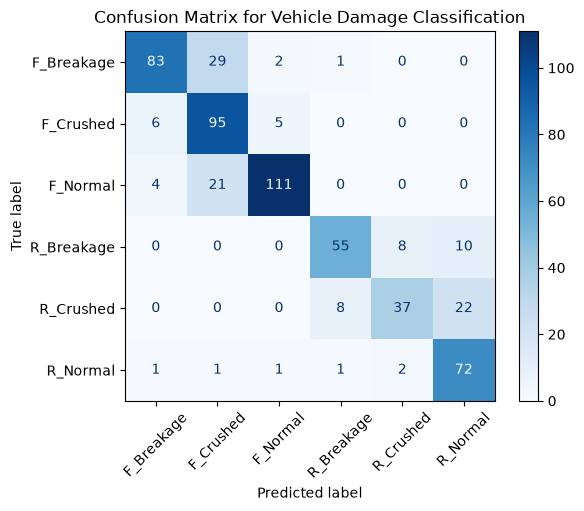

In [101]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

conf_matrix = confusion_matrix(labels, predictions, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix for Vehicle Damage Classification")
plt.show()

In [102]:
torch.save(model.state_dict(), 'saved_model.pth')